<a href="https://colab.research.google.com/github/MaximSS1309/ML_SEREDOVSKIJ_MAXM/blob/main/%D0%9B%D0%A0_6_%D1%81%D0%B5%D1%80%D0%B5%D0%B4%D0%BE%D0%B2%D1%81%D1%8C%D0%BA%D0%B8%D0%B9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Лабораторна робота № 6 — ШАБЛОН ДЛЯ СТУДЕНТІВ**

**Класифікація. Запобігання перенавчанню**

Датасет: https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset?select=diabetes_prediction_dataset.csv

Виконуйте завдання послідовно. **До аналізу кореляцій і викидів спочатку зробіть train/test split.** В усіх завданнях для дослідження кореляцій, меж IQR і асиметрії використовуйте **тільки train**. Не видаляйте викиди автоматично, не балансуйте test. Заповніть код у клітинках `TODO`, додайте короткі висновки та результати.

Потрібно навчити LogisticRegression, RidgeClassifier, SGDClassifier, SVC, вивести звіти та матриці плутанини, підібрати параметри методом HalvingGridSearchCV (`cv=3`) і показати 10 тестових прогнозів.

*Виберіть лише один зі способів завантаження даних нижче.*

In [ ]:
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

**Спосіб 1.** Завантажити CSV із комп’ютера (Google Colab)

In [ ]:

uploaded = files.upload()

In [ ]:
df = pd.read_csv('diabetes_prediction_dataset.csv.zip')
df

**Спосіб 2.** Завантажити датасет з Kaggle (Google Colab)

In [ ]:
import kagglehub

path = kagglehub.dataset_download("iammustafatz/diabetes-prediction-dataset")

print("Path to dataset files:", path)

In [ ]:
df = pd.read_csv(os.path.join(path, "diabetes_prediction_dataset.csv"))
df

Вивести інформацію про датасет

In [ ]:
df.info()

Провести дослідження категоріальних ознак

In [ ]:
print(df['gender'].value_counts())
print(df['gender'].value_counts(normalize=True).round(3))
sns.countplot(data=df, x='gender')
plt.show()

In [ ]:
print(df['smoking_history'].value_counts())
print(df['smoking_history'].value_counts(normalize=True).round(3))
sns.countplot(data=df, x='smoking_history')
plt.xticks(rotation=30)
plt.show()

In [ ]:
df

Вивести типи даних

In [ ]:
df.dtypes

Дослідити цільову змінну: перевірити баланс класів

In [ ]:
df['diabetes'].value_counts()

Висновок: визначте за результатом, чи є дисбаланс класів.

Перевірити наявність пропущених даних


In [ ]:
df.isnull().sum()

Наявність дублікатів


In [ ]:
df.duplicated().sum()

Видалити дублікати

In [ ]:
df.drop_duplicates(inplace=True)

In [ ]:
df

Ще раз перевірити баланс цільової змінної

In [ ]:
df['diabetes'].value_counts()

Побудувати гістограму для цільової змінної


In [ ]:
sns.countplot(x='diabetes', data=df, color='tab:blue')

Переглянути описові статистики **навчальної вибірки**

In [ ]:
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE

In [ ]:
from sklearn.model_selection import train_test_split
X = df.drop(columns=['diabetes'])
y = df['diabetes']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)

Закодувати категоріальні ознаки **після поділу**. Створюємо стовпці за категоріями з train; у test залишаємо точно такий самий набір стовпців.

In [ ]:
cat_cols = ['gender', 'smoking_history']

X_train = pd.get_dummies(X_train, columns=cat_cols, dtype=int)
X_test = pd.get_dummies(X_test, columns=cat_cols, dtype=int)


X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

In [ ]:
X_train.describe()

Перевірити кореляцію ознак із цільовою змінною **лише на train**

In [ ]:
corr_target = X_train.corrwith(y_train).sort_values(ascending=False)
print(corr_target)

In [ ]:
corr_matrix = X_train.corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Кореляційна матриця ознак (train)')
plt.show()

**Висновок:** які ознаки сильно корелюють між собою або з цільовою змінною? Чи потрібно видаляти ознаки? З цільовою змінною найсильніше корелюють blood_glucose_level та HbA1c_level, далі йдуть age, bmi, hypertension, heart_disease. Усі зв'язки слабкі або помірні, а ознаки gender і smoking_history майже не корелюють із diabetes.
Між собою ознаки корелюють слабко або помірно (наприклад, age з bmi, hypertension та heart_disease). Сильна від'ємна кореляція є лише між думмі-стовпцями однієї категорії, це наслідок кодування.
Видаляти ознаки не потрібно, бо сильної мультиколінеарності немає, а слабка лінійна кореляція з таргетом не означає, що ознака марна для нелінійних залежностей (наприклад, для SVC).
Усі розрахунки зроблено лише на X_train і y_train, тестові дані не використовувалися.

Перевірити викиди **лише на навчальній вибірці**

In [ ]:
continuous_cols = ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, continuous_cols):
    sns.boxplot(y=X_train[col], ax=ax, color='tab:blue')
    ax.set_title(col)
plt.tight_layout()
plt.show()

**Висновок:** викиди перевіряємо, але в цій лабораторній роботі автоматично **не видаляємо**. Екстремальні значення глюкози та HbA1c можуть бути клінічно важливими.

**Необов’язковий приклад.** Якщо потрібно видалити викиди методом IQR, межі обчислюємо **тільки на train**, видаляємо відповідні рядки з `X_train` і `y_train`, а `X_test` та `y_test` не змінюємо. У цій роботі приклад не запускаємо.

In [ ]:
# НЕОБОВ'ЯЗКОВО: опишіть, як обчислити IQR для bmi тільки на X_train.
# Якщо вирішите вилучати рядки, синхронно оновіть X_train та y_train.
# Тестові дані не змінюйте. У цій роботі викиди не видаляємо.

Перевірити асиметрію розподілів ознак **на train**

In [ ]:
X_train[continuous_cols].skew()

In [ ]:
continuous_cols = ['age', 'bmi', 'HbA1c_level', 'blood_glucose_level']

**Проміжний висновок:** опишіть баланс класів, кореляції та викиди на train. Тестову вибірку залишаємо незмінною. Баланс класів: клас 0 переважає (приблизно 91% проти 9%), дисбаланс значний, тому поряд з accuracy потрібно дивитися на precision, recall і F1 для класу 1. Розбиття зроблено зі stratify=y, тож пропорція класів у train і test однакова.
Кореляції на train: найсильніше з diabetes пов'язані blood_glucose_level та HbA1c_level, решта зв'язків слабкі. Між ознаками сильної мультиколінеарності немає, окрім дзеркальних думмі-стовпців, тому ознаки не видаляємо.
Викиди на train: викиди помітні переважно в bmi та blood_glucose_level. Їх не видаляємо, бо це реальні медичні значення. Асиметрія (за skew()) підтверджує правий хвіст у цих ознак.
Тестову вибірку не змінювали й не використовували для розрахунків, а пропуски перевірено окремо в обох вибірках.

Масштабуємо ознаки: `fit_transform` лише для train, `transform` — для test.

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Балансуємо лише навчальну вибірку за допомогою SMOTE

In [ ]:
from imblearn.over_sampling import SMOTE

print("До SMOTE:")
print(y_train.value_counts())

smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train_scaled, y_train)

print("\nПісля SMOTE:")
print(y_train_bal.value_counts())

Оголошуємо моделі

In [ ]:
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE
models = {
    'LogisticRegression': LogisticRegression(max_iter=1000, random_state=42),
    'RidgeClassifier': RidgeClassifier(random_state=42),
    'SGDClassifier': SGDClassifier(random_state=42),
    'SVC': SVC(random_state=42)
}

Навчити моделі, вивести матриці плутанини, класифікаційний звіт


=== LogisticRegression ===
              precision    recall  f1-score   support

           0       0.99      0.89      0.93     17534
           1       0.43      0.88      0.57      1696

    accuracy                           0.88     19230
   macro avg       0.71      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230



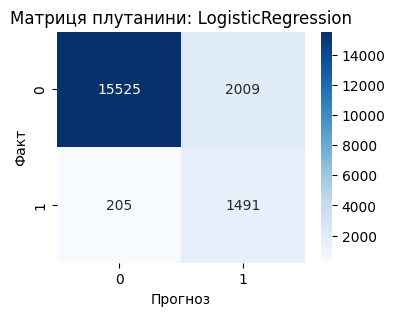

=== RidgeClassifier ===
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.43      0.88      0.58      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.88      0.76     19230
weighted avg       0.94      0.89      0.90     19230



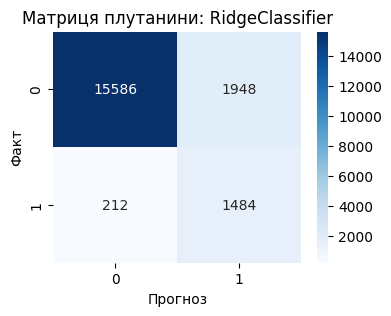

=== SGDClassifier ===
              precision    recall  f1-score   support

           0       0.99      0.86      0.92     17534
           1       0.38      0.91      0.53      1696

    accuracy                           0.86     19230
   macro avg       0.68      0.88      0.73     19230
weighted avg       0.94      0.86      0.88     19230



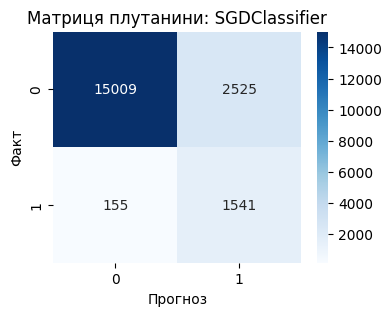

KeyboardInterrupt: 

In [37]:
trained = {}

for name, model in models.items():
    model.fit(X_train_bal, y_train_bal)
    trained[name] = model

    y_pred = model.predict(X_test_scaled)

    print(f"=== {name} ===")
    print(classification_report(y_test, y_pred))

    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(4, 3))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=[0, 1], yticklabels=[0, 1])
    plt.title(f'Матриця плутанини: {name}')
    plt.xlabel('Прогноз')
    plt.ylabel('Факт')
    plt.show()

Оптимізувати гіперпараметри


In [ ]:
param_grids = {
    'LogisticRegression': {
        'C': [0.01, 0.1, 1, 10],
        'solver': ['lbfgs', 'liblinear']
    },
    'RidgeClassifier': {
        'alpha': [0.1, 1, 10, 100]
    },
    'SGDClassifier': {
        'alpha': [0.0001, 0.001, 0.01],
        'loss': ['hinge', 'log_loss'],
        'penalty': ['l2', 'l1']
    },
    'SVC': {
        'C': [0.1, 1, 10],
        'kernel': ['linear', 'rbf']
    }
}

Підбираємо параметри методом **HalvingGridSearchCV** із `cv=3`, `scoring="f1"`. Масштабування та SMOTE виконуються в кожному навчальному згині, щоб не було витоку даних. На малих порціях для пошуку задаємо достатній мінімальний розмір навчальних даних.

In [ ]:

from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV
from imblearn.pipeline import Pipeline

In [ ]:
best_models = {}
best_scores = {}

for name, model in models.items():
    pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('smote', SMOTE(random_state=42)),
        ('model', model)
    ])


    grid = {f'model__{k}': v for k, v in param_grids[name].items()}

    search = HalvingGridSearchCV(
        pipe,
        grid,
        cv=3,
        scoring='f1',
        min_resources=300,
        factor=3,
        random_state=42,
        n_jobs=-1
    )


    search.fit(X_train, y_train)

    best_models[name] = search.best_estimator_
    best_scores[name] = search.best_score_

    print(f"=== {name} ===")
    print("Оптимальні параметри:", search.best_params_)
    print("Найкращий F1 (CV):", round(search.best_score_, 4))


    y_pred = search.best_estimator_.predict(X_test)
    print(classification_report(y_test, y_pred))

Вибрати найкращу модель за середнім F1 на кросвалідації (а не за тестовою вибіркою)

In [ ]:
best_name = max(best_scores, key=best_scores.get)
best_model = best_models[best_name]

print("Найкраща модель:", best_name)
print("Середній F1 на крос-валідації:", round(best_scores[best_name], 4))

for name, score in sorted(best_scores.items(), key=lambda x: -x[1]):
    print(f"{name}: {score:.4f}")

In [ ]:
rng = np.random.RandomState(42)
idx = rng.choice(len(X_test), size=10, replace=False)

sample = X_test.iloc[idx]
y_pred_sample = best_model.predict(sample)

result = pd.DataFrame({
    'індекс': sample.index,
    'істинний клас': y_test.iloc[idx].values,
    'передбачений клас': y_pred_sample
})
result['збіг'] = result['істинний клас'] == result['передбачений клас']
print(result)

**Підсумкові висновки (заповніть самостійно):**
1. Дисбаланс, кореляції та викиди на train

У train 70130 прикладів класу 0 і 6786 класу 1, тобто діабет становить близько 8,8%. Дисбаланс значний, тому accuracy оманлива і потрібно дивитися на precision, recall та F1 для класу 1. Кореляція на train показала, що найсильніше з diabetes пов'язані blood_glucose_level та HbA1c_level (r = [...] і [...]), решта зв'язків слабкі. Між ознаками сильної мультиколінеарності немає, окрім дзеркальних думмі-стовпців, тому ознаки не видаляли. Перевірка викидів показала їх переважно в bmi та blood_glucose_level, асиметрія (skew = [...]) підтверджує правий хвіст. Викиди не видаляли, бо це реальні медичні значення.

2. Найкращі F1 і recall та обрана модель

За F1 для класу 1 найкраще себе показала [модель] (F1 = [...]), за recall для класу 1 найкраща [модель] (recall = [...]). За середнім F1 на крос-валідації обрано [best_name] (CV F1 = [...]). Загалом моделі після SMOTE мають високий recall, але нижчий precision: частина здорових пацієнтів помилково позначається як хворі.

3. Гіперпараметри та помилки в матриці плутанини

Оптимальні параметри: LogisticRegression: [...]; RidgeClassifier: [...]; SGDClassifier: [...]; SVC: [...]. У матрицях плутанини видно два типи помилок: хибнопозитивні (здорових визнано хворими) та хибнонегативні (хворих пропущено). Через SMOTE перших зазвичай більше, а других менше. Для медичної задачі пропуск хворого небезпечніший, тому високий recall виправданий, хоча й ціною додаткових хибних тривог.

4. Навіщо тест відкладати, а масштабування й SMOTE робити лише на train

Тестова вибірка імітує нові, невідомі моделі дані, тому вона не повинна впливати на жоден крок підготовки. Якщо рахувати середнє та стандартне відхилення на всіх даних, у модель потрапляє інформація з test (витік даних). Якщо застосувати SMOTE до test або до всього датасету, синтетичні приклади, створені на основі справжніх, можуть опинитися в різних частинах поділу, а test перестане відображати реальний розподіл класів. Тому масштабування й SMOTE виконуються тільки на train, а в крос-валідації всередині Pipeline на кожному фолді окремо. Модель обирали за CV F1, а не за тестом, щоб тест залишився чесною фінальною перевіркою.